# GA4 이커머스 구매 퍼널 분석 (재구현)
INNER CIRCLE 9기 팀 프로젝트(2026.07) **H1, H3 분석을 다시 구현한 노트북**입니다. 원본 노트북을 보관하지 못해, 팀 최종 보고서의 분석 정의와 정제 기준을 따라 코드를 새로 작성했습니다(2026.11).

- 데이터: `bigquery-public-data.ga4_obfuscated_sample_ecommerce` (Google Merchandise Store)
- 기간: 규모 확인은 2020-11-01 ~ 2021-01-31 전체, 분석은 측정 오류 구간(11/1~11/10, transaction_id 단일값)을 뺀 2020-11-11 ~ 2021-01-31
- 퍼널(6단계): 세션 → 상품 조회 → 장바구니 → 결제 진입 → 결제정보 입력 → 구매 완료
- 신규/재방문: `ga_session_number = 1` / `>= 2`
- 실행 환경: Google Colab + BigQuery (무료 샌드박스로 실행 가능)

## 0. BigQuery 연결
`PROJECT_ID`에 본인 Google Cloud 프로젝트 ID를 넣고 실행합니다.

In [15]:
PROJECT_ID = "your-gcp-project-id"  # 본인 프로젝트 ID로 변경

from google.colab import auth
auth.authenticate_user()
from google.cloud import bigquery
client = bigquery.Client(project=PROJECT_ID)
run = lambda q: client.query(q).to_dataframe()

## 분석 함수

In [16]:
"""GA4 퍼널 분석 함수 모음. BigQuery 집계 결과(DataFrame)를 받아 지표를 계산한다."""
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

STEPS = ["s1_session", "s2_view_item", "s3_add_to_cart",
         "s4_begin_checkout", "s5_add_payment_info", "s6_purchase"]
STEP_LABELS = {"s1_session": "세션", "s2_view_item": "상품 조회", "s3_add_to_cart": "장바구니",
               "s4_begin_checkout": "결제 진입", "s5_add_payment_info": "결제정보 입력",
               "s6_purchase": "구매 완료"}


def step_pass_rates(seg: pd.DataFrame) -> pd.DataFrame:
    """세그먼트별 직전 단계 대비 통과율(%)과 재방문-신규 격차(%p)."""
    s = seg.set_index("segment")[STEPS]
    rows = []
    for prev, nxt in zip(STEPS[:-1], STEPS[1:]):
        r = {"구간": f"{STEP_LABELS[prev]} → {STEP_LABELS[nxt]}"}
        for g in s.index:
            r[g] = round(100 * s.loc[g, nxt] / s.loc[g, prev], 1) if s.loc[g, prev] else None
        rows.append(r)
    out = pd.DataFrame(rows)
    if {"new", "returning"} <= set(out.columns):
        out["격차(%p)"] = (out["returning"] - out["new"]).round(1)
    return out


def checkout_completion(seg: pd.DataFrame) -> pd.Series:
    """결제 진입 유저 중 구매 완료 비율(%)."""
    s = seg.set_index("segment")
    return (100 * s["s6_purchase"] / s["s4_begin_checkout"]).round(1)


def ztest_step(seg: pd.DataFrame, prev: str, nxt: str):
    """재방문 vs 신규의 특정 구간 통과율 차이에 대한 2-표본 비율검정."""
    s = seg.set_index("segment")
    counts = [s.loc["returning", nxt], s.loc["new", nxt]]
    nobs = [s.loc["returning", prev], s.loc["new", prev]]
    z, p = proportions_ztest(counts, nobs)
    return z, p


def channel_summary(ch: pd.DataFrame) -> pd.DataFrame:
    """채널별 구매 전환율, 신규 비중, 신규/재방문 전환율(%)."""
    t = ch.copy()
    t["구매전환율(%)"] = (100 * t.purchasers / t.users).round(2)
    t["신규비중(%)"] = (100 * t.new_users / t.users).round(1)
    t["신규 전환율(%)"] = (100 * t.new_purchasers / t.new_users).round(2)
    t["재방문 전환율(%)"] = (100 * t.returning_purchasers / t.returning_users).round(2)
    return t.sort_values("구매전환율(%)")


def impact_scenarios(seg: pd.DataFrame, aov_new: float) -> pd.DataFrame:
    """신규 결제완료율을 끌어올렸을 때의 추가 구매 건수와 매출(USD) 추정."""
    s = seg.set_index("segment")
    comp = 100 * s["s6_purchase"] / s["s4_begin_checkout"]  # 반올림 전 값으로 계산
    base, target = comp["new"], comp["returning"]
    n_checkout = s.loc["new", "s4_begin_checkout"]
    rows = [("현재", base)]
    if base + 10 < target:
        rows.append(("+10%p 개선", base + 10))
    rows.append(("재방문 수준까지", target))
    out = []
    for name, rate in rows:
        extra = round(n_checkout * (rate - base) / 100)
        out.append({"시나리오": name, "신규 결제완료율(%)": round(rate, 1),
                    "추가 구매(건)": extra, "추가 매출(USD)": round(extra * aov_new)})
    return pd.DataFrame(out)


In [17]:
import matplotlib.pyplot as plt
!pip -q install koreanize-matplotlib
import koreanize_matplotlib
pd.set_option("display.width", 250)

## 1. 데이터 규모 확인

In [18]:
SQL_EVENTS = """-- 이벤트별 발생 건수와 유저 수 (데이터 규모 확인용)
WITH events AS (
  SELECT user_pseudo_id, event_name
  FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
  WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20210131'
)
SELECT event_name, COUNT(*) AS events, COUNT(DISTINCT user_pseudo_id) AS users
FROM events
GROUP BY event_name
ORDER BY events DESC
"""
events = run(SQL_EVENTS)
events.head(20)

,event_name,events,users
0,page_view,1350428,269792
1,user_engagement,1058721,213004
2,scroll,493072,138098
3,view_item,386068,61252
4,session_start,354970,267116
5,first_visit,257462,257314
6,view_promotion,190104,102443
7,add_to_cart,58543,12545
8,begin_checkout,38757,9715
9,select_item,31007,13180


## 2. H1: 채널별 구매 전환율과 신규 비중
전환율이 가장 낮은 채널이 정말 비효율적인지, 신규 유저 구성 때문인지 확인합니다.

In [19]:
SQL_CHANNEL = """-- 기간: 2020-11-11 ~ 2021-01-31. 11/1~11/10은 transaction_id가 단일값으로 기록된 측정 오류 구간이라 팀 정제 기준에 따라 제외한다.
-- 유입 채널(traffic_source.medium, 유저 최초 유입 기준)별 유저 수, 신규/재방문 구성, 구매 유저 수.
-- 신규 유저: 기간 내 최대 ga_session_number = 1 / 재방문 유저: >= 2
WITH events AS (
  SELECT
    user_pseudo_id,
    event_name,
    traffic_source.medium AS medium,
    (SELECT value.int_value FROM UNNEST(event_params) WHERE key = 'ga_session_number') AS session_number
  FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
  WHERE _TABLE_SUFFIX BETWEEN '20201111' AND '20210131'
),
users AS (
  SELECT
    user_pseudo_id,
    ANY_VALUE(medium)                    AS medium,
    MAX(session_number)                  AS max_session,
    LOGICAL_OR(event_name = 'purchase')  AS purchased
  FROM events
  GROUP BY user_pseudo_id
)
SELECT
  CASE medium
    WHEN 'cpc' THEN 'CPC'
    WHEN 'organic' THEN 'Organic'
    WHEN '(none)' THEN 'Direct'
    WHEN 'referral' THEN 'Referral'
  END AS channel,
  COUNT(*)                                  AS users,
  COUNTIF(max_session = 1)                  AS new_users,
  COUNTIF(max_session >= 2)                 AS returning_users,
  COUNTIF(purchased)                        AS purchasers,
  COUNTIF(max_session = 1 AND purchased)    AS new_purchasers,
  COUNTIF(max_session >= 2 AND purchased)   AS returning_purchasers
FROM users
WHERE medium IN ('cpc', 'organic', '(none)', 'referral')   -- '<Other>', '(data deleted)' 제외
GROUP BY channel
ORDER BY channel
"""
ch = run(SQL_CHANNEL)
chs = channel_summary(ch)
chs

,channel,users,new_users,returning_users,purchasers,new_purchasers,returning_purchasers,구매전환율(%),신규비중(%),신규 전환율(%),재방문 전환율(%)
0,CPC,12192,10804,1388,140,59,81,1.15,88.6,0.55,5.84
2,Organic,90006,76388,13618,1203,313,890,1.34,84.9,0.41,6.54
1,Direct,58015,47560,10455,900,220,680,1.55,82.0,0.46,6.5
3,Referral,38729,28836,9893,887,121,766,2.29,74.5,0.42,7.74


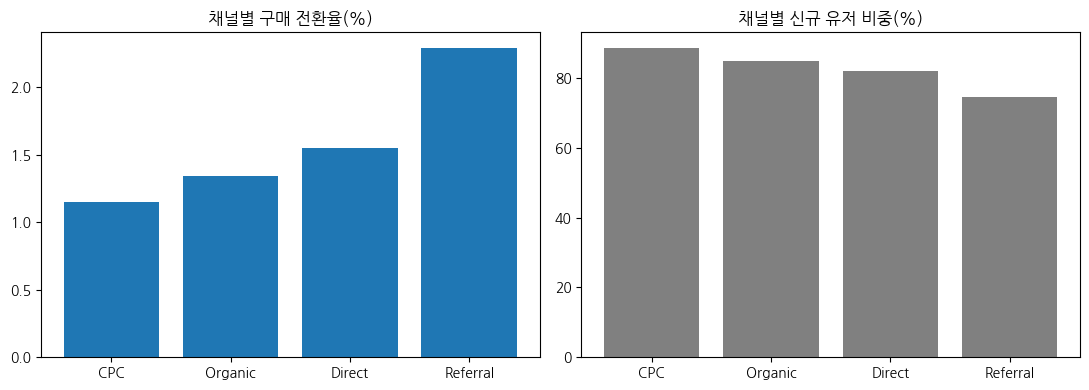

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(chs.channel, chs["구매전환율(%)"]); ax[0].set_title("채널별 구매 전환율(%)")
ax[1].bar(chs.channel, chs["신규비중(%)"], color="gray"); ax[1].set_title("채널별 신규 유저 비중(%)")
plt.tight_layout(); plt.show()

## 3. H3: 신규 vs 재방문 6단계 퍼널
어느 구간에서 신규가 가장 크게 무너지는지 찾습니다.

In [21]:
SQL_SEGMENT = """-- 기간: 2020-11-11 ~ 2021-01-31. 11/1~11/10은 transaction_id가 단일값으로 기록된 측정 오류 구간이라 팀 정제 기준에 따라 제외한다.
-- 6단계 퍼널을 신규(ga_session_number = 1)와 재방문(>= 2)으로 나눠 단계별 도달 유저 수를 센다.
-- 분석 단위: user_pseudo_id x 세그먼트 (같은 유저가 신규와 재방문 양쪽에 나타날 수 있음)
WITH events AS (
  SELECT
    user_pseudo_id,
    event_name,
    (SELECT value.int_value FROM UNNEST(event_params) WHERE key = 'ga_session_number') AS session_number
  FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
  WHERE _TABLE_SUFFIX BETWEEN '20201111' AND '20210131'
),
flags AS (
  SELECT
    IF(session_number = 1, 'new', 'returning') AS segment,
    user_pseudo_id,
    LOGICAL_OR(event_name = 'session_start')    AS s1_session,
    LOGICAL_OR(event_name = 'view_item')        AS s2_view_item,
    LOGICAL_OR(event_name = 'add_to_cart')      AS s3_add_to_cart,
    LOGICAL_OR(event_name = 'begin_checkout')   AS s4_begin_checkout,
    LOGICAL_OR(event_name = 'add_payment_info') AS s5_add_payment_info,
    LOGICAL_OR(event_name = 'purchase')         AS s6_purchase
  FROM events
  WHERE session_number IS NOT NULL
  GROUP BY segment, user_pseudo_id
)
SELECT
  segment,
  COUNTIF(s1_session)          AS s1_session,
  COUNTIF(s2_view_item)        AS s2_view_item,
  COUNTIF(s3_add_to_cart)      AS s3_add_to_cart,
  COUNTIF(s4_begin_checkout)   AS s4_begin_checkout,
  COUNTIF(s5_add_payment_info) AS s5_add_payment_info,
  COUNTIF(s6_purchase)         AS s6_purchase
FROM flags
GROUP BY segment
ORDER BY segment
"""
seg = run(SQL_SEGMENT)
seg

,segment,s1_session,s2_view_item,s3_add_to_cart,s4_begin_checkout,s5_add_payment_info,s6_purchase
0,new,234336,46970,8851,5151,2408,1651
1,returning,45875,13953,4679,3794,3147,2533


In [22]:
rates = step_pass_rates(seg)
display(rates)
worst = rates.loc[rates["격차(%p)"].idxmax()]
print(f"최대 격차 구간: {worst['구간']} (신규 {worst['new']}% vs 재방문 {worst['returning']}%, 격차 {worst['격차(%p)']}%p)")
print("결제 진입 대비 구매 완료율(%):"); print(checkout_completion(seg))

,구간,new,returning,격차(%p)
0,세션 → 상품 조회,20.0,30.4,10.4
1,상품 조회 → 장바구니,18.8,33.5,14.7
2,장바구니 → 결제 진입,58.2,81.1,22.9
3,결제 진입 → 결제정보 입력,46.7,82.9,36.2
4,결제정보 입력 → 구매 완료,68.6,80.5,11.9


최대 격차 구간: 결제 진입 → 결제정보 입력 (신규 46.7% vs 재방문 82.9%, 격차 36.2%p)
결제 진입 대비 구매 완료율(%):
segment
new          32.1
returning    66.8
dtype: Float64


In [23]:
i = rates["격차(%p)"].idxmax()
z, p = ztest_step(seg, STEPS[i], STEPS[i + 1])
print(f"2-표본 비율검정: z = {z:.2f}, p = {p:.2e}")

2-표본 비율검정: z = 34.88, p = 1.68e-266


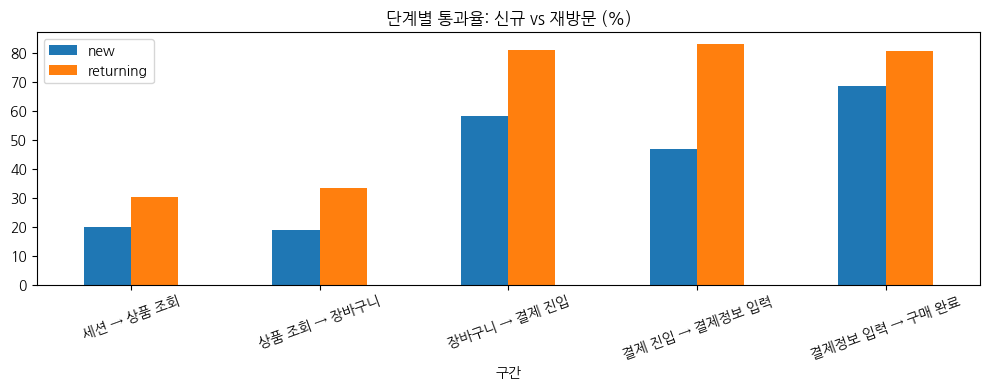

In [24]:
ax = rates.set_index("구간")[["new", "returning"]].plot.bar(figsize=(10, 4), rot=20)
ax.set_title("단계별 통과율: 신규 vs 재방문 (%)"); plt.tight_layout(); plt.show()

## 4. 매출 임팩트 추정
신규의 결제 완료율을 재방문 수준까지 올렸을 때의 추가 구매와 매출을 추정합니다. 결제 진입 유저 수가 그대로라는 가정의 상한값입니다.

In [25]:
SQL_AOV = """-- 기간: 2020-11-11 ~ 2021-01-31. 11/1~11/10은 transaction_id가 단일값으로 기록된 측정 오류 구간이라 팀 정제 기준에 따라 제외한다.
-- 매출 임팩트 추정에 쓸 구매 1건당 평균 매출(USD), 신규/재방문 세그먼트별
WITH events AS (
  SELECT
    event_name,
    ecommerce.purchase_revenue_in_usd AS revenue,
    (SELECT value.int_value FROM UNNEST(event_params) WHERE key = 'ga_session_number') AS session_number
  FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
  WHERE _TABLE_SUFFIX BETWEEN '20201111' AND '20210131'
)
SELECT
  IF(session_number = 1, 'new', 'returning') AS segment,
  COUNT(*)      AS purchase_events,
  AVG(revenue)  AS avg_order_value_usd
FROM events
WHERE event_name = 'purchase' AND revenue > 0 AND session_number IS NOT NULL
GROUP BY segment
ORDER BY segment
"""
aov = run(SQL_AOV).set_index("segment")
display(aov)
impact = impact_scenarios(seg, aov.loc["new", "avg_order_value_usd"])
impact

,purchase_events,avg_order_value_usd
segment,,
new,1734,65.133795
returning,3088,71.384391


,시나리오,신규 결제완료율(%),추가 구매(건),추가 매출(USD)
0,현재,32.1,0,0
1,+10%p 개선,42.1,515,33544
2,재방문 수준까지,66.8,1788,116459


## 5. 결과 요약 (텍스트)

In [26]:
print(chs[["channel", "users", "구매전환율(%)", "신규비중(%)"]].to_string(index=False))
print(); print(rates.to_string(index=False))
print(); print("결제 완료율(%):", checkout_completion(seg).to_dict())
print(); print(impact.to_string(index=False))

 channel  users  구매전환율(%)  신규비중(%)
     CPC  12192      1.15     88.6
 Organic  90006      1.34     84.9
  Direct  58015      1.55     82.0
Referral  38729      2.29     74.5

             구간  new  returning  격차(%p)
     세션 → 상품 조회 20.0       30.4    10.4
   상품 조회 → 장바구니 18.8       33.5    14.7
   장바구니 → 결제 진입 58.2       81.1    22.9
결제 진입 → 결제정보 입력 46.7       82.9    36.2
결제정보 입력 → 구매 완료 68.6       80.5    11.9

결제 완료율(%): {'new': 32.1, 'returning': 66.8}

    시나리오  신규 결제완료율(%)  추가 구매(건)  추가 매출(USD)
      현재         32.1         0           0
+10%p 개선         42.1       515       33544
재방문 수준까지         66.8      1788      116459


## 6. 결론
**H1. CPC의 낮은 전환율은 채널보다 신규 유저 구성 때문입니다.**
- CPC 구매 전환율은 1.15%로 4개 채널 중 가장 낮고, Referral(2.29%)이 가장 높습니다.
- CPC는 신규 유저 비중이 88.6%로 가장 높습니다. 채널 예산을 줄이기 전에 신규 유저를 재방문으로 전환하는 효과부터 검증해야 합니다.

**H3. 신규 유저의 최대 병목은 결제 진입 → 결제정보 입력 단계입니다.**
- 이 구간 통과율은 신규 46.7% vs 재방문 82.9%로, 격차 36.2%p가 6개 구간 중 가장 큽니다(2-표본 비율검정 z = 34.88, p < 0.001).
- 결제 진입 유저의 구매 완료율은 신규 32.1% vs 재방문 66.8%로 약 2.1배 차이입니다.

**임팩트.** 신규의 결제 완료율을 재방문 수준까지 올리면 기간 내 약 1,788건, 약 $116,000의 추가 매출이 가능합니다(결제 진입 유저 수가 그대로라는 가정의 상한).

**제안.** 결제까지 온 신규 유저를 리타겟팅으로 재방문시키고, 결제 단계에서 총액(배송비, 세금) 사전 노출과 간편결제로 첫 구매의 불안을 줄입니다. 효과는 A/B 테스트로 검증한 뒤 확대합니다.

**한계:** 공개 샘플은 일부 필드가 비식별 처리돼 있어 광고비와 결제 화면(UX) 데이터가 없습니다. 매출 추정은 상한값입니다.